#16-385 Computer Vision

## Programming Assignment 1: Image Filtering and Hough Transform

In this assignment, you will be implementing some basic image processing algorithms and putting them together to build a Hough Transform based line detector. Your code will be able to fit lines to edges in images. We have included a number of images for you to test your line detector code on. Like most vision algorithms, the Hough Transform uses a number of parameters whose optimal values are (unfortunately) data dependent, that is, a set of parameter values that works really well on one image might not be best for another image. By running your code on the test images you will learn about what these parameters do and how changing their values effects performance.

Many of the algorithms you will be implementing as part of this assignment are functions in OpenCV (Open Computer Vision Library). You are not allowed to use calls to these functions in this assignment, unless otherwise specified. You may, however, compare your output to the output generated by these functions to make sure you are on the right track.

---
## Instructions

1. **Integrity and collaboration:** Students are encouraged to work in groups but each student must submit their own work. If you work as a group, include the names of your collaborators in your write up. Code should NOT be shared or copied. Please DO NOT use external code unless permitted. Plagiarism is strongly prohibited and may lead to failure of this course.

2. **Start early!** Especially those not familiar with Python.

3. **Questions:** If you have any questions, please look at Piazza first. Other students may have encountered the same problem, and it may be solved already. If not, post your question on the discussion board. Teaching staff will respond as soon as possible.

4. **File paths:** Excluding the assignment setup, please make sure that any file paths that you use are relative and not absolute. Not `cv2.imread('/content/drive/MyDrive/hw1/data/xyz.jpg')` but `cv2.imread('./data/xyz.jpg')`.

5. **Submission:** Handing in your assignments involves **two** separate submissions via Gradescope: one for your code + results, and one for a pdf version of your code showing any requested results. The submission time will be the later of the two timestamps associated with these submissions. For example, if you submit your full solution before the deadline and submit your write-up 1 day late, your assignment will be considered 1 day late. Once submitted, **double check that the pdf can be viewed from within Gradescope and that you submitted the correct files!!**


### Assignment Setup
Run the next cell to use the bundled files. Local Jupyter uses this repository; Google Colab clones it without requiring Google Drive access.


In [ ]:
from pathlib import Path
import os
import subprocess
import sys

# Find the complete bundle when launched from the repository or an assignment folder.
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "requirements.txt").is_file()
                  and all((p / f"hw{i}").is_dir() for i in range(4))), None)
if REPO_ROOT is None and Path("/content").is_dir():
    try:
        import google.colab
    except ImportError:
        pass
    else:
        REPO_ROOT = Path("/content/CMU-16-385-Computer-Vision")
        if not REPO_ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1",
                            "https://github.com/pedier/CMU-16-385-Computer-Vision.git",
                            str(REPO_ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(REPO_ROOT / "requirements.txt")], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Clone the complete repository and launch Jupyter from it.")
os.chdir(REPO_ROOT / "hw1")
Path("results").mkdir(exist_ok=True)
print("Working directory:", Path.cwd())


In [ ]:
# All assignment assets are already included in this repository.


In [ ]:
# The setup cell has selected the assignment working directory.


---
## Section 1: Implementation

### 1.1 Convolution (20 points)

Write a function that convolves an image with a given convolution filter:
```
img1 = myImageFilter(img0, h)
```
As input, this function takes a greyscale image `img0` and a convolution filter stored in matrix `h`. The output of the function should be an image `img1` of the same size as `img0` which results from convolving `img0` with `h`. You can assume that the filter `h` is odd sized along both dimensions (e.g., 3x3, or 3x5). You will need to handle boundary cases on the edges of the image. For example, when you place a convolution mask on the top left corner of the image, most of the filter mask will lie outside the image. One solution is to output a zero value at all these locations, the better thing to do is to pad the image such that pixels lying outside the image boundary have the same intensity value as the nearest pixel that lies inside the image. You can call NumPy's pad function to pad the array; [read about the different modes available for padding here](https://numpy.org/doc/stable/reference/generated/numpy.pad.html). However, your code cannot call on `convolve`, `correlate`, `fftconvolve`, or any other similar functions.

You may compare your output to these functions for comparison and debugging. As with most of your solutions in the course, you should aim to write code that executes fast. To do so, this function should be vectorized as much as possible, meaning that you should be relying as much as possible on mathematical functions that operate on vectors and matrices (e.g., element-wise addition and multiplication operations). Avoid indexing into matrix elements one at a time (or do so sparingly), as this will significantly slow down your code. [Examples and meaning of vectorization can be found here](https://www.pythonlikeyoumeanit.com/Module3_IntroducingNumpy/VectorizedOperations.html).

When implementing your convolution solution, try to limit your solution to **two** for loops. Also note the computational overhead associated with each loop iteration is not negligible in practice; make sure to **minimize the number of iterations** in each for loop *(hint: you should assume that the kernel `h` is smaller than the image `img1`)*.

In [8]:
import numpy as np

def myImageFilter(img0, h):
  img0 = np.asarray(img0, dtype=np.float64)
  h = np.asarray(h, dtype=np.float64)
  img_height, img_width = img0.shape
  h_height, h_width = h.shape   # both should be odd

  # first, let's pad the image, using edge mode which I prefer
  # the size of the padding depends on the size of the kernel
  pad_height = h_height // 2
  pad_width = h_width // 2
  padded = np.pad(img0, ((pad_height, pad_height), (pad_width, pad_width)), mode='edge')

  # convolution requires flipping of kernel
  h_flipped = np.flip(np.flip(h, axis=0), axis=1)

  img1 = np.zeros((img_height, img_width), dtype=np.float64)

  # instead of looping over the image, let's loop over the kernel
  for i in range(h_height):
    for j in range(h_width):
      img1 += h_flipped[i, j] * padded[i:i+img_height, j:j+img_width]

  return img1

### 1.2 Edge Detection (20 points)

Write a function that finds edge intensity and orientation in an image:
```
img1 = myEdgeFilter(img0, sigma)
```
The function will input a greyscale image `img0` and scalar `sigma`. `sigma` is the standard deviation of the Gaussian smoothing kernel to be used before edge detection. The function will output `img1`: the edge magnitude image.

First, use your convolution function to smooth out the image with the specified Gaussian kernel. This helps reduce noise and spurious fine edges in the image. Use [`scipy.signal.windows.gaussian`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.windows.gaussian.html) to get the kernel for the Gaussian filter. The size of the Gaussian filter should depend on `sigma` (e.g., `hsize = 2 * ceil(3 * sigma) + 1)`.

The edge magnitude image `img1` can be calculated from image gradients in the x direction and y direction. To find the image gradient `imgx` in the x direction, convolve the smoothed image with the x-oriented Sobel filter. Similarly, find image gradient `imgy` in the y direction by convolving the smoothed image with the y-oriented Sobel filter. You can also output `imgx` and `imgy` if needed.

In many cases, the high gradient magnitude region along an edge will be quite thick. For finding lines its best to have edges that are a single pixel wide. Towards this end, make your edge filter implement **non-maximum suppression**. Non-maximum suppression (NMS) is an algorithm used to find local maxima using the property that the value of a local maximum is greater than its neighbors. To use NMS for edge thinning, for each pixel, look at the two neighboring pixels along the gradient direction; if either of those pixels has a larger gradient magnitude, then set the edge magnitude at the center pixel to zero. To simplify the implementation, you can quantize the gradient direction into one of 0, 45, 90, and 135 degrees, and compare the center pixel with two of the 8 neighbors in the 3x3 window, according to the gradient direction. The value of a center pixel is set to 0 if its gradient magnitude is less than either one or both of its neighbors' values, along the gradient direction.

For example, if the gradient direction of a pixel is 45 degrees (i.e., the image edge is oriented at 135 degrees), we compare its gradient magnitude with the north-east and south-west neighbors and suppress its magnitude if it's not greater than these two neighbors. When the gradient direction at a pixel is 90 degrees, we compare the pixel to its north and south neighbors and suppress its magnitude if it's not greater than these two neighbors. The same logic applies for a gradient direction of 0 degrees and 135 degrees.

Your code cannot call on OpenCV's Canny function, or any other similar functions. You may use Canny for comparison and debugging. A sample result is shown below.

![Figure 1](https://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw1/edge_detection.png)

When implementing your edge filter solution, limit your solution to **no** for loops.

In [9]:
import numpy as np
from scipy.signal.windows import gaussian # For gaussian kernel

def myEdgeFilter(img0, sigma):
  img0 = np.asarray(img0, dtype=np.float64)
  sigma = float(sigma)

  hsize = int(2 * np.ceil(3 * sigma) + 1)
  g_1d = gaussian(hsize, sigma)
  g_2d = np.outer(g_1d, g_1d)
  g_nor = g_2d / np.sum(g_2d)

  smoothed = myImageFilter(img0, g_nor)

  sb_x = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=np.float64)
  sb_y = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], dtype=np.float64)
  imgx = myImageFilter(smoothed, sb_x)
  imgy = myImageFilter(smoothed, sb_y)

  mag = np.sqrt(imgx ** 2 + imgy ** 2)
  dir = (180 + np.rad2deg(np.arctan2(imgy, imgx))) % 180

  # pad a circle of zeros
  mag_padded = np.pad(mag, ((1, 1), (1, 1)), mode='constant', constant_values=0)

  Nnbr = mag_padded[:-2, 1:-1]
  Snbr = mag_padded[2:, 1:-1]
  Wnbr = mag_padded[1:-1, :-2]
  Enbr = mag_padded[1:-1, 2:]
  NWnbr = mag_padded[:-2, :-2]
  NEnbr = mag_padded[:-2, 2:]
  SWnbr = mag_padded[2:, :-2]
  SEnbr = mag_padded[2:, 2:]

  # partition into intervals
  in_0 = ((dir < 22.5) | (dir >= 157.5))
  in_45 = ((dir >= 22.5) & (dir < 67.5))
  in_90 = ((dir >= 67.5) & (dir < 112.5))
  in_135 = ((dir >= 112.5) & (dir < 157.5))

  keep_0 = (in_0 & (mag >= Wnbr) & (mag >= Enbr))
  keep_45 = (in_45 & (mag >= NEnbr) & (mag >= SWnbr))
  keep_90 = (in_90 & (mag >= Nnbr) & (mag >= Snbr))
  keep_135 = (in_135 & (mag >= NWnbr) & (mag >= SEnbr))

  kept = (keep_0 | keep_45 | keep_90 | keep_135)
  img1 = np.where(kept, mag, 0.0)
  return img1


### 1.3 The Hough Transform (20 points)

Write a function that applies the Hough Transform to an edge magnitude image:
```
[img_hough, rhoScale, thetaScale] = myHoughTransform(img_threshold, rhoRes, thetaRes)
```
`img_threshold` is the edge magnitude image, thresholded to ignore pixels with a low edge filter response. The scalar `rhoRes` is the distance resolution of the Hough transform accumulator in pixels, and the scalar `thetaRes` is the angular resolution of the accumulator in radians. `img_hough` is the Hough transform accumulator that contains the number of “votes” for all the possible lines passing through the image. `rhoScale` and `thetaScale` are the arrays of $\rho$ and $\theta$ values over which `myHoughTransform` generates the Hough transform matrix `img_hough`. For example, if `rhoScale[i]` = $\pi$ and `thetaScale[j]` = $\theta_j$, then `img_hough[i,j]` contains the votes for $\rho = \pi$ and $\theta = \theta_j$.

Each pixel $(x,y)$ above the thresholded image img threshold is a possible point on a line and votes in the Hough transform for all the lines it could be a part of. Parametrize lines in terms of $\theta$ and $\rho$ such that $\rho = x \cos \theta + y \sin \theta$ where $\theta \in [0, 2\pi]$ and $\rho \in [0,M]$. $M$ should be large enough to accommodate all lines that could lie in an image. Each line in the image corresponds to a unique pair $(\rho,\theta)$ in this range. Therefore, $\theta$ values corresponding to negative $\rho$ values are invalid, and you should not count those votes.

The accumulator resolution needs to be selected carefully. If the resolution is set too low, the estimated line parameters might be inaccurate. If resolution is too high, run time will increase and votes for one line might get split into multiple cells in the array.

A sample visualization of `img_hough` is shown in below.

![Figure 1](https://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw1/hough_transform.png)

In [10]:
import numpy as np

def myHoughTransform(Im, rhoRes, thetaRes):
  Im_height, Im_width = Im.shape
  rhoRes = float(rhoRes)
  thetaRes = float(thetaRes)

  farthest = np.sqrt((Im_height - 1) ** 2 + (Im_width - 1) ** 2)
  numrho = int(np.ceil(farthest / rhoRes)) + 1

  rhoScale = np.arange(numrho, dtype=np.float64) * rhoRes

  thetaScale = np.arange(0.0, 2.0 * np.pi, thetaRes, dtype=np.float64)

  img_hough = np.zeros((np.size(rhoScale), np.size(thetaScale)), dtype=np.float64)

  edge_y, edge_x = np.where(Im > 0)
  sintheta, costheta = np.sin(thetaScale), np.cos(thetaScale)

  for i in range(np.size(thetaScale)):
    rho = edge_x * costheta[i] + edge_y * sintheta[i]
    nonneg = (rho >= 0)

    # identify, then vote
    rho_ind = np.floor(rho[nonneg] / rhoRes + 0.5).astype(np.int64)
    img_hough[:, i] = np.bincount(rho_ind, minlength=np.size(rhoScale))

  return img_hough, rhoScale, thetaScale

### 1.4 Finding Lines (15 points)

Write a function that uses the Hough transform output to detect lines,
```
[rhos, thetas] = myHoughLines(img_hough, nLines)
```
where `img_hough` is the Hough transform accumulator, and `nLines` is the number of lines to return. Outputs `rhos` and `thetas` are both vectors of length `nLines` that contain the row and column coordinates of peaks in `img_hough` (i.e., the lines found in the image).

Ideally, you would want this function to return the $\rho$ and $\theta$ coordinates for the `nLines` highest scoring cells in the Hough accumulator. But for every cell in the accumulator corresponding to a real line (likely to be a locally maximal value), there will probably be a number of cells in the neighborhood that also scored high but should not be selected. These non maximal neighbors can be removed using non-maximal suppression once again. Note that this non-maximal suppression step is different from the one performed earlier. Here you will consider all neighbors of a pixel (e.g., within a window of size NxN), not just the two pixels lying along the gradient direction. At every pixel in the NxN window, the filter suppresses the value of the center pixel (by setting its value to 0) if its value is not greater than the value of the neighbors (in the original image). In your implementation, you have the option to make use of the [OpenCV function dilate](https://docs.opencv.org/5.0/main_modules/imgproc_filter.html#dilate).

Once you have suppressed the non-maximal cells in the Hough accumulator, return the coordinates corresponding to the strongest peaks in the accumulator. Once you have $\rho$ and $\theta$ for each line in an image, the code that follows should fit a red line to edges in your image based on the values of $\rho$ and $\theta$. The green line segments represent the output of OpenCV's HoughLinesP. Note that your code can not call on OpenCV's HoughLines function, HoughLinesP function, or other similar functions.


In [11]:
import numpy as np
import cv2  # For cv2.dilate function

def myHoughLines(H, nLines):
  H = np.asarray(H, dtype=np.float64)
  nms = 5
  kernel = np.ones((nms, nms), dtype=np.uint8)
  kernel[nms//2, nms//2] = 0  # we have to exclude the center
  H_dilated = cv2.dilate(H, kernel, borderType=cv2.BORDER_CONSTANT, borderValue=0)

  peaks = ((H > 0) & (H_dilated < H)) # greater than all neighbors - keep
  peaks_coor = np.argwhere(peaks)
  peaks_val = H[peaks]

  # need to sort, take the first nLines
  sorted_indices = np.argsort(peaks_val)[::-1][:nLines]
  sorted_peaks_coor = peaks_coor[sorted_indices]

  rhos = sorted_peaks_coor[:, 0].astype(np.int64)
  thetas = sorted_peaks_coor[:, 1].astype(np.int64)
  return rhos, thetas

We have included the following code that takes care of reading in images
from a directory, making function calls to the various steps of the Hough transform and generates images showing the output and some of the intermediate steps. You are free to modify the code as you want, but note that TAs will run the original code while grading. Please make sure your code runs correctly with the original code and generates the required output images.

In [12]:
import cv2
import numpy as np
import os

datadir    = 'data'      # the directory containing the images
resultsdir = 'results'   # the directory for dumping results

# parameters
sigma     = 2
threshold = 0.03
rhoRes    = 2
thetaRes  = np.pi / 90
nLines    = 15
# end of parameters

for file in os.listdir(datadir):
    if file.endswith('.jpg'):

        file = os.path.splitext(file)[0]

        # read in images
        img = cv2.imread('%s/%s.jpg' % (datadir, file))

        if (img.ndim == 3):
            img = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

        img = np.float32(img) / 255

        # actual Hough line code function calls
        img_edge = myEdgeFilter(img, sigma)
        img_threshold = np.float32(img_edge > threshold)
        [img_hough, rhoScale, thetaScale] = myHoughTransform(img_threshold, \
                                                             rhoRes, thetaRes)
        [rhos, thetas] = myHoughLines(img_hough, nLines)

        lines = cv2.HoughLinesP(np.uint8(255 * img_threshold), rhoRes, thetaRes, \
                                50, minLineLength = 20, maxLineGap = 5)

        # everything below here just saves the outputs to files
        fname = '%s/%s_01edge.png' % (resultsdir, file)
        cv2.imwrite(fname, 255 * np.sqrt(img_edge / img_edge.max()))

        fname = '%s/%s_02threshold.png' % (resultsdir, file)
        cv2.imwrite(fname, 255 * img_threshold)

        fname = '%s/%s_03hough.png' % (resultsdir, file)
        cv2.imwrite(fname, 255 * img_hough / img_hough.max())

        fname = '%s/%s_04lines.png' % (resultsdir, file)
        img_lines = np.dstack([img,img,img])

        # display line results from myHoughLines function in red
        for k in np.arange(nLines):
            a = np.cos(thetaScale[thetas[k]])
            b = np.sin(thetaScale[thetas[k]])

            x0 = a*rhoScale[rhos[k]]
            y0 = b*rhoScale[rhos[k]]

            x1 = int(x0 + 1000*(-b))
            y1 = int(y0 + 1000*(a))

            x2 = int(x0 - 1000*(-b))
            y2 = int(y0 - 1000*(a))

            cv2.line(img_lines,(x1,y1),(x2,y2),(0,0,255),1)

        # display line segment results from cv2.HoughLinesP in green, to serve
        # as a comparison
        for coords in ([] if lines is None else lines.reshape(-1, 4)):
            cv2.line(img_lines, (int(coords[0]), int(coords[1])),
                     (int(coords[2]), int(coords[3])), (0, 255, 0), 1)

        cv2.imwrite(fname, 255 * img_lines)

---
## Section 2: Experiments

### 2.1 Write-up (15 points)

Use the code above to run your Hough detector on the image set and generate intermediate output images. Include the set of intermediate outputs for two images in your write-up; this means include at least two images from myImageFilter, two images from myEdgeFilter, and two images from myHoughTransform. Did your code work well on all the images with a single set of parameters? How did the optimal set of parameters vary with images? Which step of the algorithm causes the most problems? Did you find any changes you could make to your code or algorithm that improved performance? In your write-up, you should describe how well your code worked on different images, what effect do the parameters have and any improvements you made to your code to make it work better. Make sure to spend time crafting a clearly-written and complete write-up documenting your work to obtain full marks.

I would like to include image 5 and image 10. The two original images are shown below:
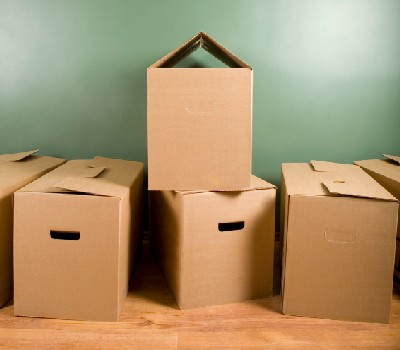

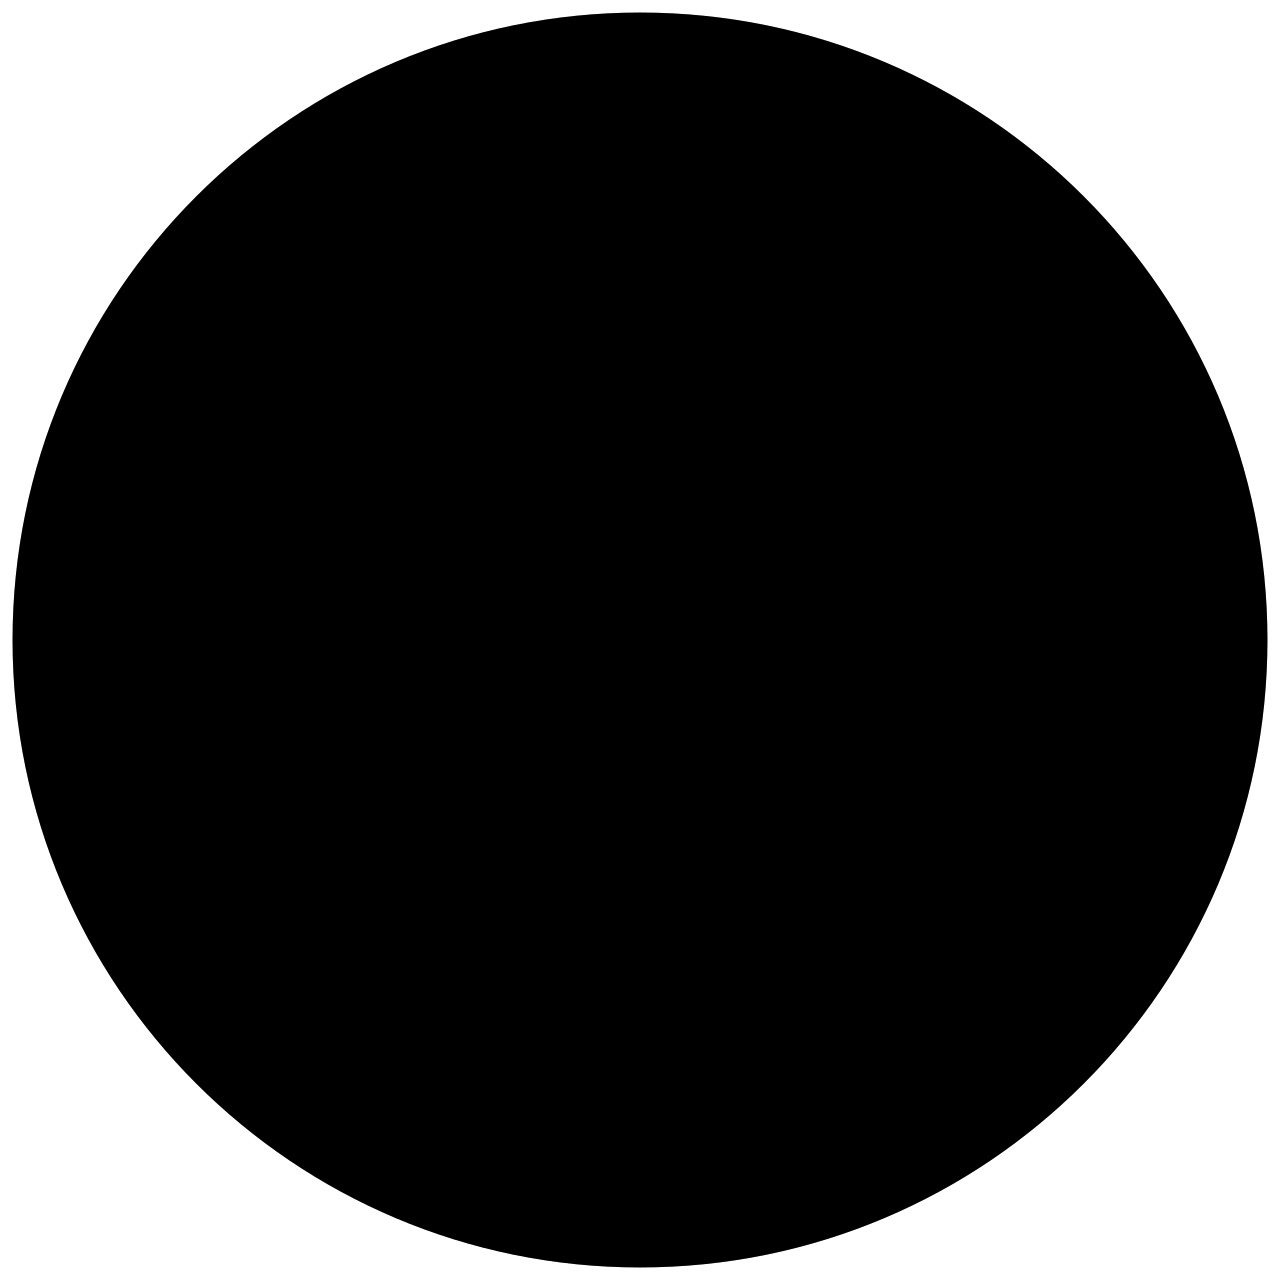

After applying *myImageFilter*:

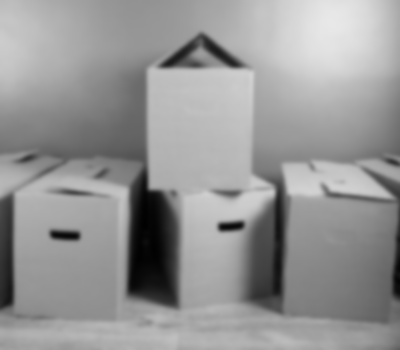

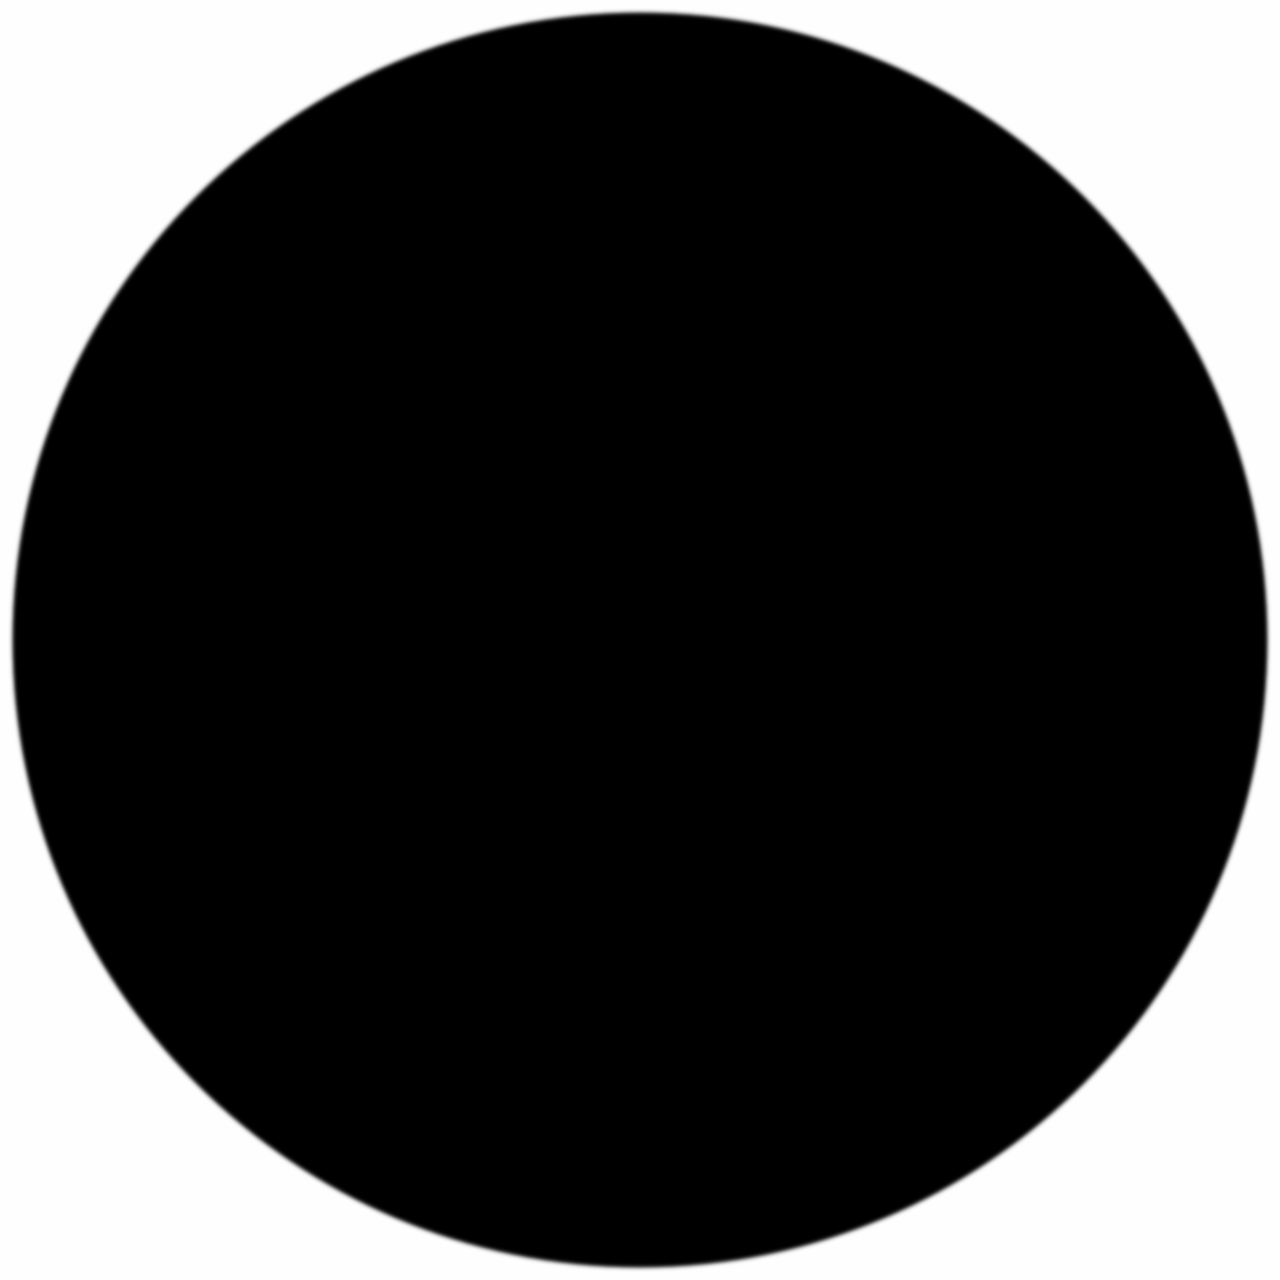


After applying *myEdgeFilter*:

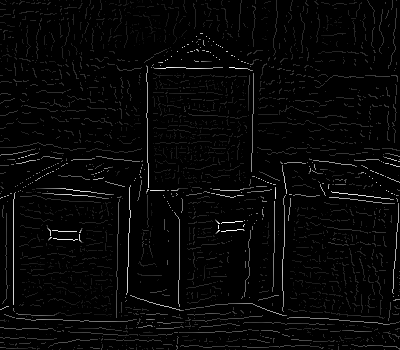

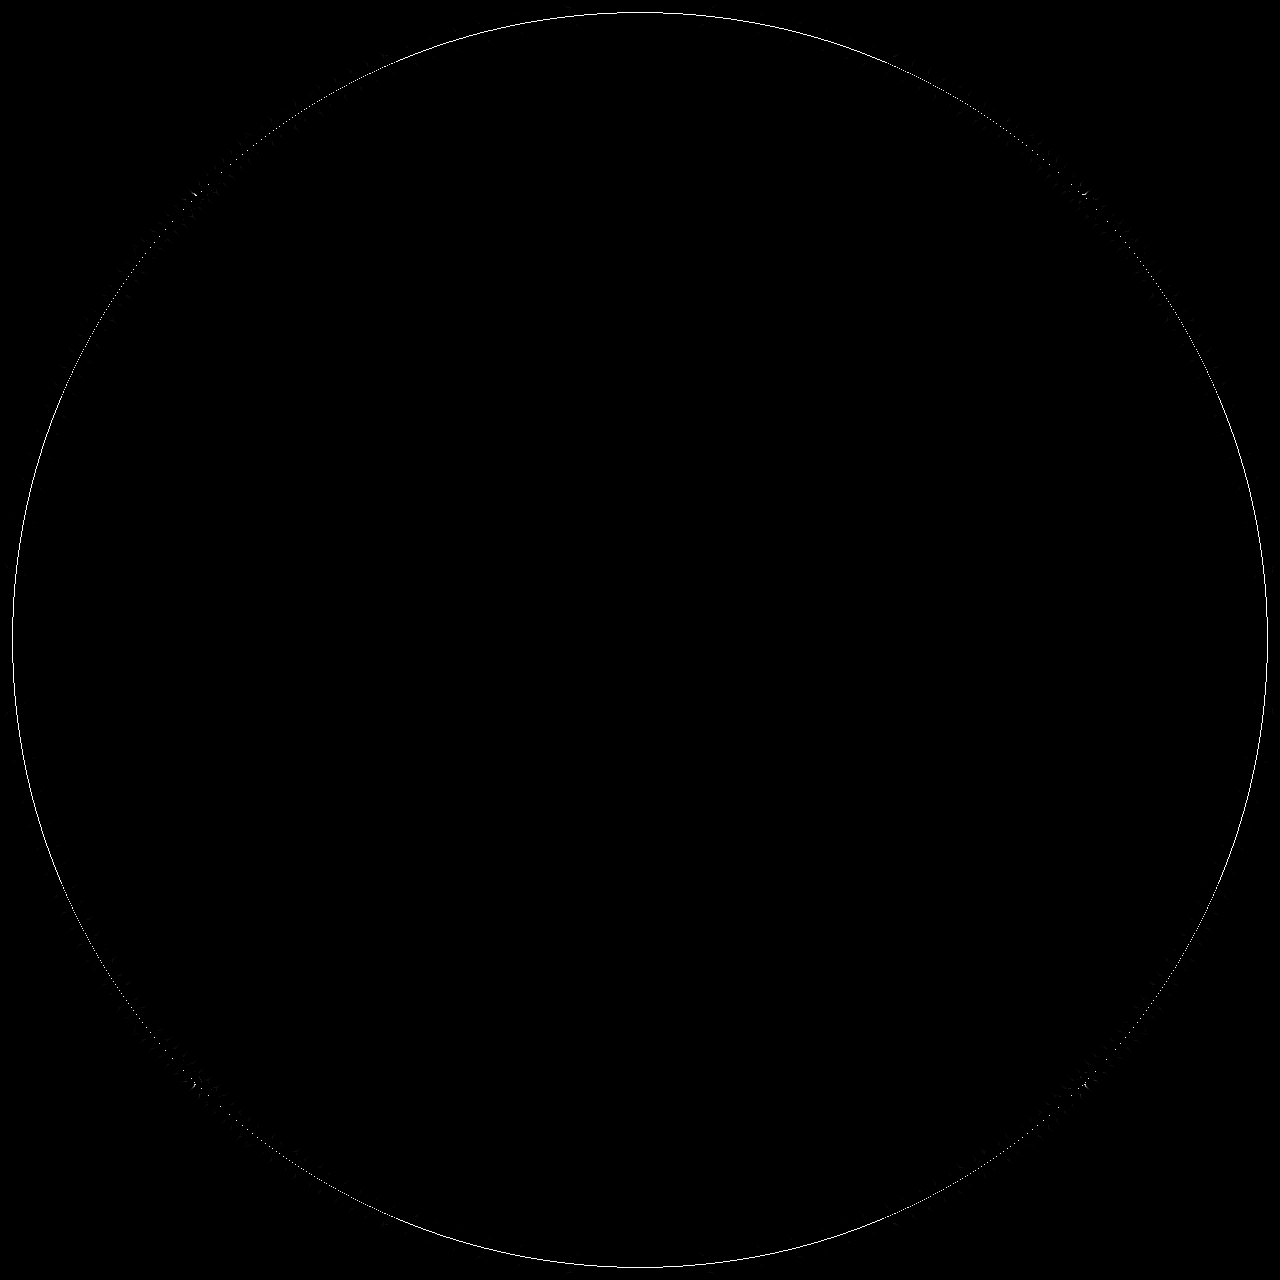

*(Threholds)*

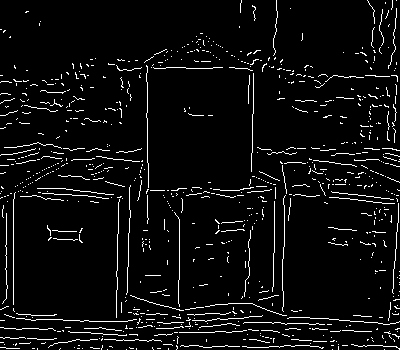

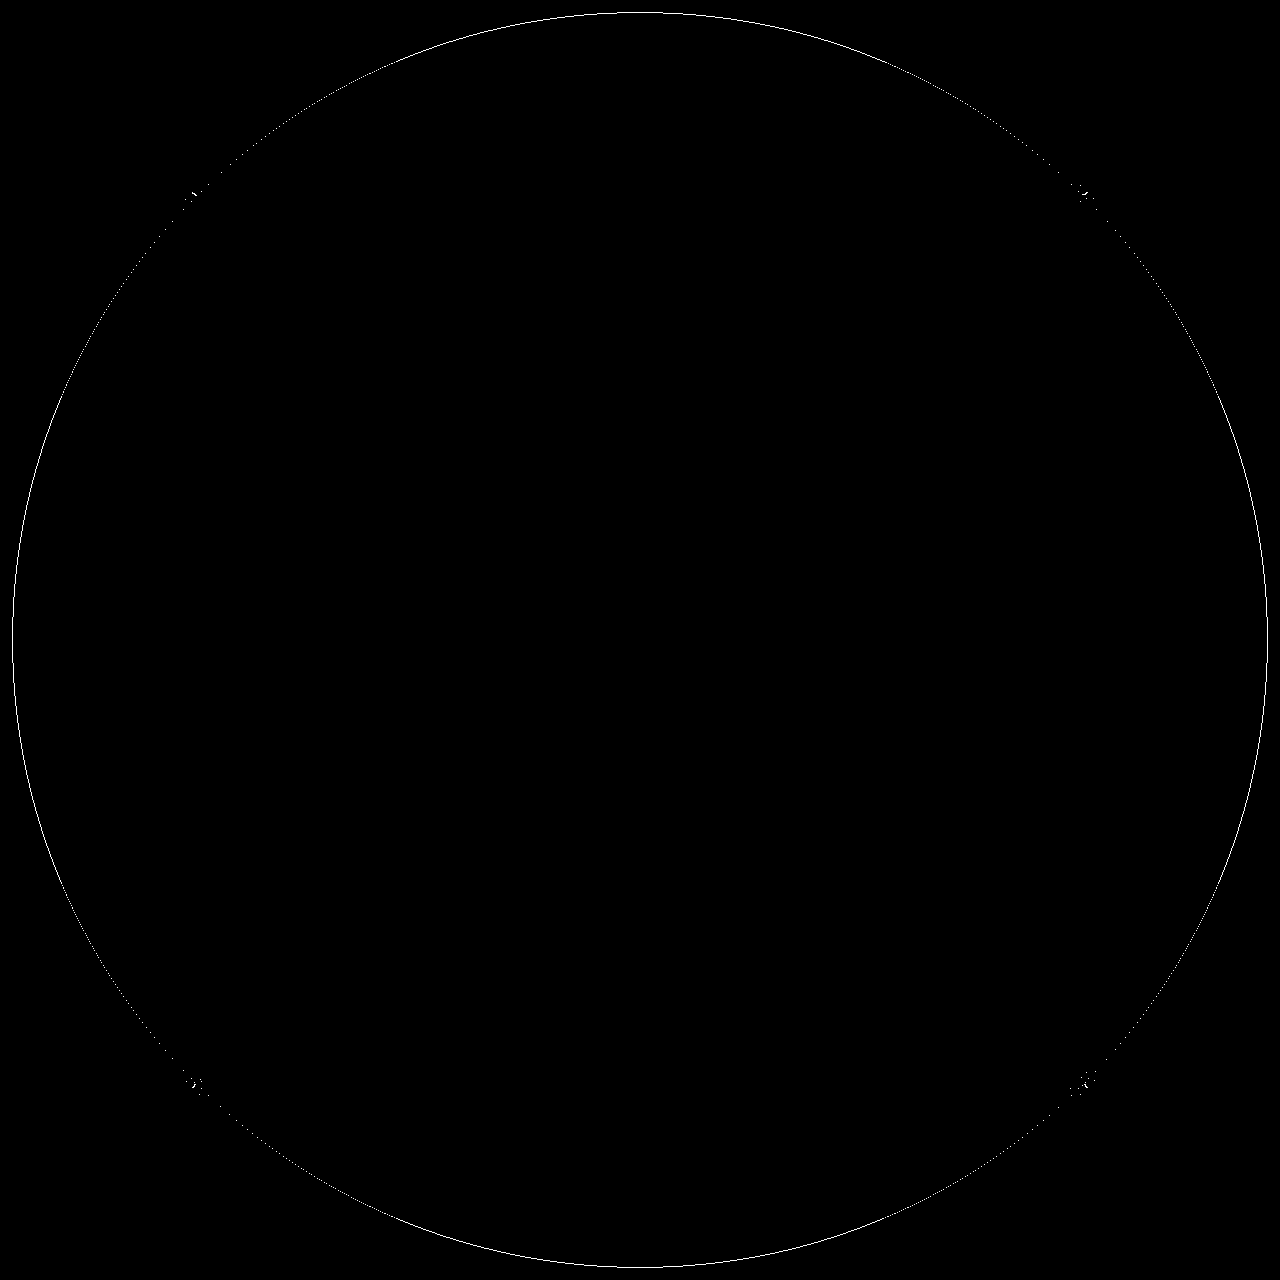

After applying *myHoughTransform*:

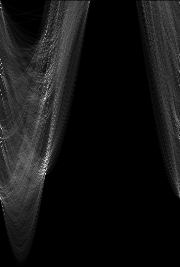

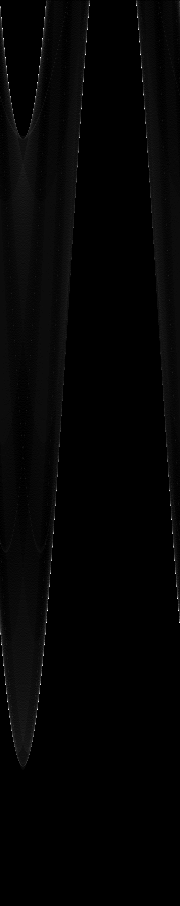

*(Lines)*


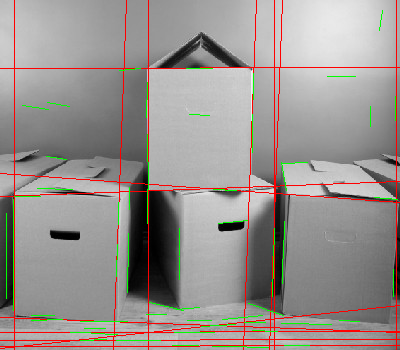


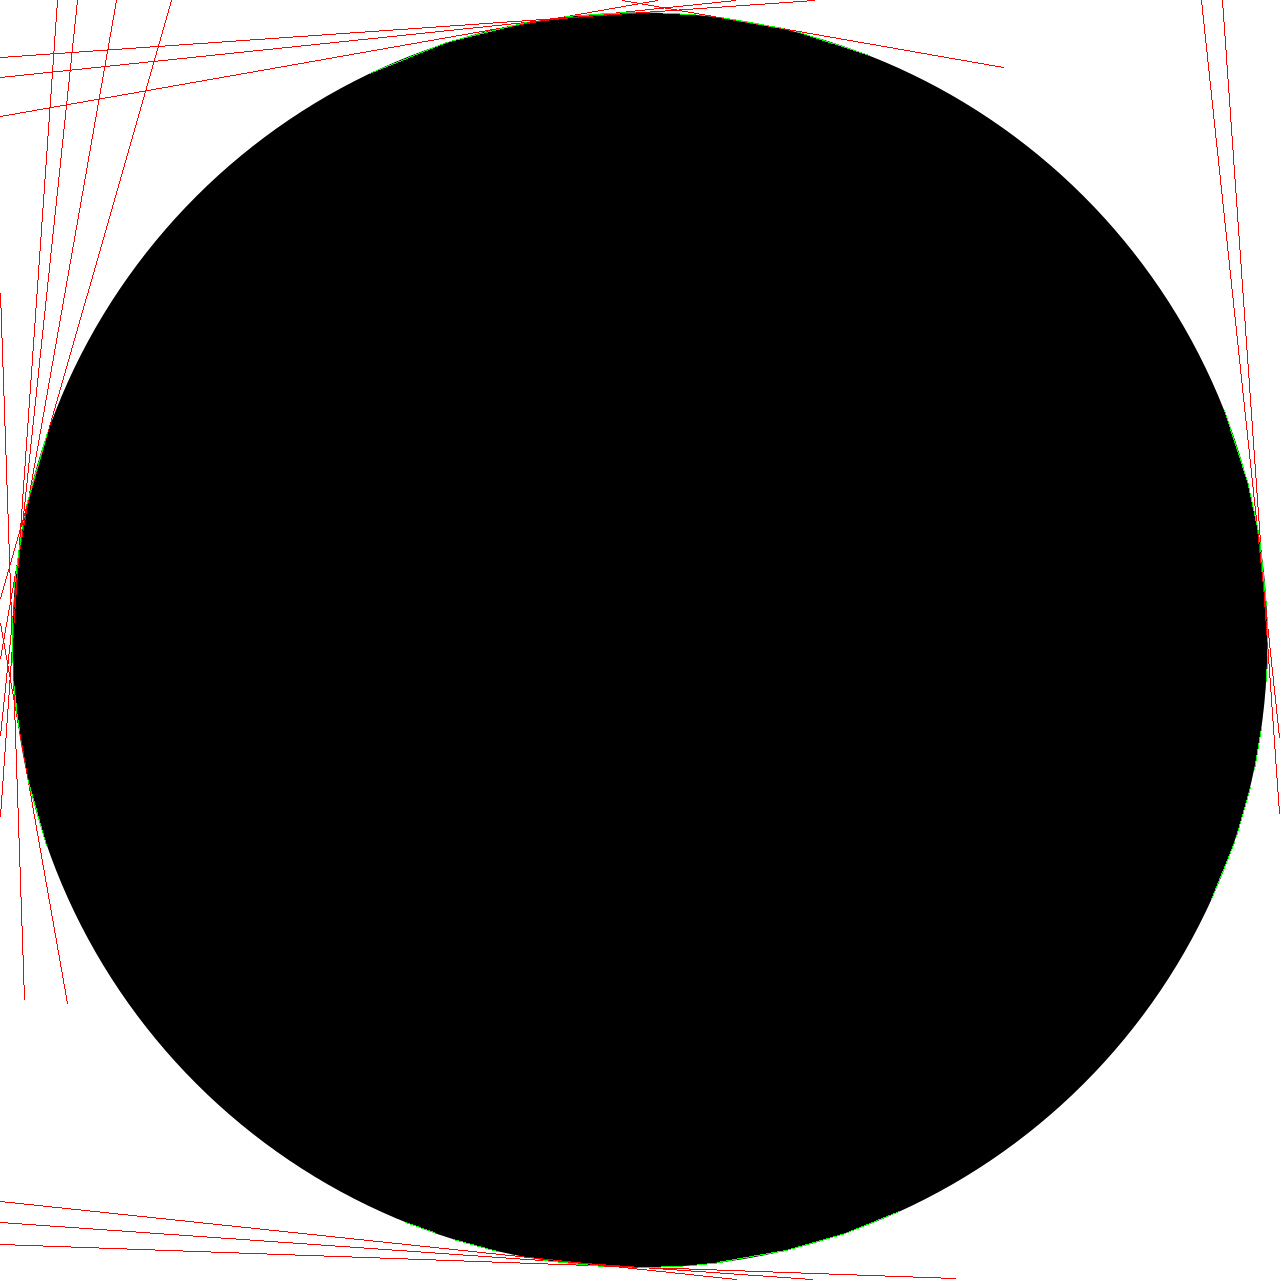

**Write-up**

I used the same set of parameters for all the images, but it did not work well. Here is a good example (image 5) and a bad example (image 10). Image 5 contains long, straight edges, and we observe that many red lines are aligned with the boundaries of the boxes, although there are also some duplicate and irrelevant lines. Overall, the detection is quite accurate and successul. However, it did not work well on Image 10, which is a simple circle. At first, the edge detector very precisely extracted the circular boundary, but the straight-line Hough transform could not represent the circle. The red lines were mostly clusters of tangents to the circle. They could not give any meaningdul information about the boundaries.

As far as I am concerned, the "optimal set of parameters" is just a case-by-case issue depending on the features of the images. For example, in image 5, we would like to remove the weak background textures and thus reduce false votes for Hough transform, so we could use a slightly higher edge threshold. We could also use a larger Hough NMS window to reduce the number of duplicate lines around the same boundary. I do find reducing nLines sometimes also worked in preventing weaker, minor peaks from being returned. However, for image 10, it could be hard too fix just by tweaking  cannot be fixed simply by tweaking the parameters. No matter how you change the parameters, it would just return tangents of the circle at different position. The fundamental solution is to switch to circular Hough transform. In general, I would say parameter is like a tradeoff - for example, if you increase the threshold too hard, yes, you are able to remove weaker and noisy edges but meanwhile, you are also removing useful, robust edges. For every image, there is such subtle but unique balance. That is why the optimal set of parameters differ case by case.

Other observations regarding the parameters: Increasing sigma is effective in removing noise but could blur weak edges. Smaller rhoRes and thetaRes is more precise, but might result in a split in votes across neighboring bins. Increasing nLines can return more lines, but some or many of them could be weak or irrelevant.

I believe the selection of peaks in the Hough transform caused the most problems. In Image 5, thick, noisy, imperfect edges produced several nearby peaks in the Hough accumulator. This caused a trouble of a cluster of multiple red lines representing the same boundary. For Image 10, it is also the problem with the Hough transform because the lines are not selected correspondingly to a circular object. This shows great limitation in the range of geometry that fits this Hough transform. I do believe the images after edge detection are awesome, but problems arise after you pass them into Hough transform.

I would definitely love to increase the NMS window in Hough to suppress more duplicate peaks. We can also reduce nLines when we only have few meaningful lines - we do not have to include everything. We can also include circular Hough transform for those images with circular geometries. Last but not least, I think it would be great if we can design a minimum vote policy in Hough (for example, we only accept a peak if at least a specific number of votes are attached to it). This means we do not always return exactly nLines. However, in this way, we are able to abandon the weak peaks.


### Generate your PDF

Run this cell LAST to generate your PDF. You will be prompted to grant permission. Please click "Select all" and then "Continue." This allows Colab to access the notebook contents to create the PDF (it does not access anything outside your notebook). It may take ~1 minute to complete-please be patient and do not rerun the cell. The PDF (including both your code and its output) will automatically download to your Downloads folder.

### Optional PDF export
Use Jupyter's **Save and Export Notebook As** menu, or Colab's **File → Print**. PDF export is separate from running the project and requires no Drive authorization.
